# ส่วนที่ 2: วิเคราะห์ข้อมูล

โหลดตารางรายวันจาก `daily_clean.csv` (ได้จากไฟล์ clean) แล้วคำนวณสมดุลน้ำ ความเสี่ยงภัยแล้ง สถิติ กราฟ และโมเดล

In [4]:
%pip install pandas numpy matplotlib seaborn scikit-learn scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 3. เตรียมไลบรารีและรูปแบบกราฟ

In [45]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

from scipy.stats import mannwhitneyu
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

BLUE, ORANGE = "#2a78b5", "#e8833a"
MEAN_C, MED_C = "#222222", "#d62728"
month_names = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e5e5e5", "axes.axisbelow": True,
    "axes.titleweight": "bold", "font.size": 10,
})

## โหลดข้อมูลรายวันที่ clean แล้ว

In [29]:
import os
IN_PATH = os.path.abspath('daily_clean.csv')
if not os.path.exists(IN_PATH):
    raise FileNotFoundError(f"ไม่พบ {IN_PATH} กรุณารัน water_01_clean.ipynb ก่อน และวางสองไฟล์ไว้โฟลเดอร์เดียวกัน")
daily = pd.read_csv(IN_PATH, index_col=0, parse_dates=True)
print(daily.shape)


(2459, 12)


## 4. สร้างข้อมูลรายวันและคำนวณสมดุลน้ำ/ความเสี่ยงภัยแล้ง

คงสูตรและค่าพารามิเตอร์เดิม เพื่อให้ผลลัพธ์ตัวเลขไม่เปลี่ยน

In [30]:
# ================= B) สมดุลน้ำและฤดู (กำหนดจากช่วง train เท่านั้น) =================
KC = 1.0                       # สัมประสิทธิ์พืช ปรับตามพืชจริง
TRAIN_END = "2024-12-31"       # ใช้กำหนดฤดูและ soil_limit

daily["etc"] = daily["et0"] * KC
daily["balance"] = daily["rain"] - daily["etc"]
daily["balance14"] = daily["balance"].rolling(14).sum()
daily["year"] = daily.index.year
daily["month"] = daily.index.month

monthly = daily[["rain", "etc", "balance"]].resample("MS").sum(min_count=1)
ok_days = daily[["rain", "etc"]].notna().all(axis=1).resample("MS").sum()
monthly = monthly[ok_days == monthly.index.days_in_month]      # เก็บเฉพาะเดือนที่ครบ
m_train = monthly[:TRAIN_END]
by_month = m_train.groupby(m_train.index.month).mean()
wet_months = by_month[by_month["balance"] > 0].index
daily["season"] = np.where(daily["month"].isin(wet_months), "wet", "dry")

# ================= C) ความเสี่ยงแล้ง =================
dry_day = daily["rain"] < 1
daily["dry_streak"] = dry_day.groupby((~dry_day).cumsum()).cumsum()

soil_limit = daily.loc[:TRAIN_END, "soil"].quantile(0.15)
daily["score"] = ((daily["soil"] < soil_limit).astype(int)
                  + (daily["balance14"] < -30).astype(int)
                  + (daily["dry_streak"] >= 10).astype(int))
daily["risk"] = daily["score"] >= 2

# ================= เช็กผล (ต้องอยู่ท้ายเซลล์ หลังสร้างคอลัมน์ครบแล้ว) =================
need = ["etc", "balance", "balance14", "year", "month", "season",
        "dry_streak", "score", "risk"]
print("daily:", daily.shape, "| คอลัมน์ที่ยังขาด:", [c for c in need if c not in daily.columns])
print("NaN ทั้งตาราง:", int(daily.isna().sum().sum()))
print("soil:", round(daily["soil"].min(), 3), "-", round(daily["soil"].max(), 3), "(ต้องราว 0.27-0.50)")
print(by_month.round(1))
print("เดือนฤดูฝน:", list(wet_months), "| soil_limit =", round(soil_limit, 3))
print(daily.isna().sum()[lambda s: s > 0])   # ควรเห็นเฉพาะ balance14 = 13

daily: (2459, 21) | คอลัมน์ที่ยังขาด: []
NaN ทั้งตาราง: 13
soil: 0.266 - 0.504 (ต้องราว 0.27-0.50)
             rain    etc  balance
time_local                       
1            10.4  134.5   -124.1
2            51.7  127.6    -76.0
3           112.4  136.9    -24.5
4           135.2  135.4     -0.2
5           286.2  122.7    163.5
6           368.3  105.4    262.9
7           477.0   99.4    377.7
8           393.0  107.9    285.2
9           530.9   88.3    442.6
10          339.6   97.1    242.5
11           73.2  113.2    -39.9
12           18.4  128.4   -110.0
เดือนฤดูฝน: [5, 6, 7, 8, 9, 10] | soil_limit = 0.289
balance14    13
dtype: int64


## 5. สถิติเชิงพรรณนา

In [16]:
# เลือกตัวแปรสำหรับสรุปสถิติ
cols = ["rain", "et0", "tmax", "vpd", "rh", "rad", "wind", "soil"]

# สถิติเชิงพรรณนา การเบ้ของข้อมูล และค่าเฉลี่ยแยกฤดูกาล
print(daily[cols].describe().round(2))
print(daily[cols].skew().round(2))
print(daily.groupby("season")[cols].mean().round(2))


          rain      et0     tmax      vpd       rh      rad     wind     soil
count  2459.00  2459.00  2459.00  2459.00  2459.00  2459.00  2459.00  2459.00
mean      7.82     3.82    30.62     0.67    82.60   203.27     1.92     0.41
std       9.66     0.99     2.04     0.44    11.60    49.37     0.84     0.08
min       0.00     0.68    21.80     0.02    43.25    33.12     0.44     0.27
25%       0.20     3.18    29.30     0.33    76.94   174.42     1.31     0.33
50%       4.30     3.94    30.60     0.55    86.25   212.17     1.79     0.45
75%      12.90     4.55    32.00     0.94    91.17   239.33     2.36     0.48
max     122.10     6.51    36.60     2.28    99.38   306.58     6.60     0.50
rain    2.61
et0    -0.43
tmax   -0.19
vpd     0.84
rh     -1.02
rad    -0.72
wind    1.08
soil   -0.56
dtype: float64
         rain   et0   tmax   vpd     rh     rad  wind  soil
season                                                     
dry      2.25  4.31  31.47  0.98  74.54  222.08  2.05  0.34

## 6. กราฟสำรวจข้อมูลและเปรียบเทียบฤดูกาล

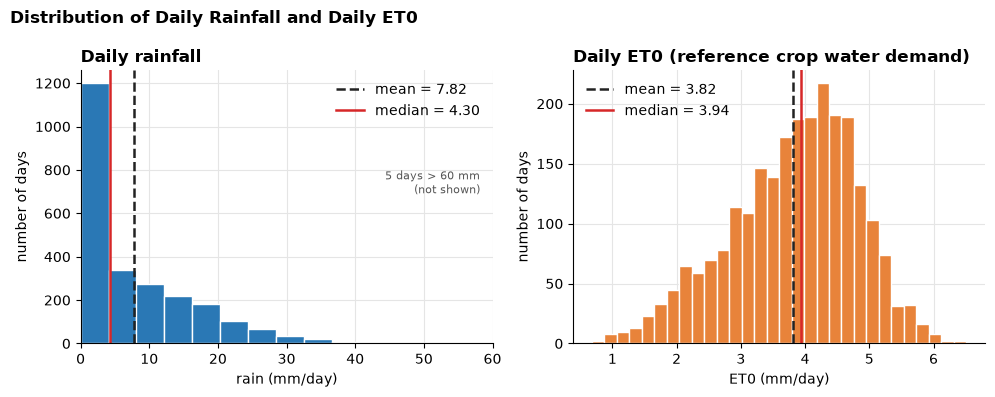

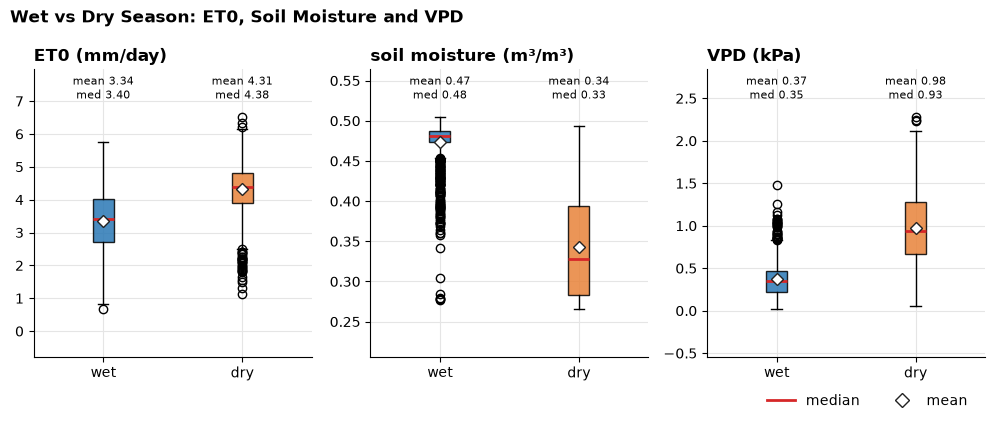

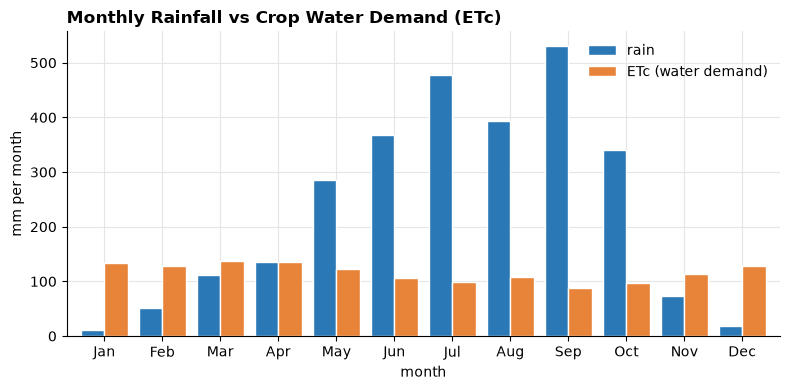

In [31]:
# ---------- กราฟ 1: histogram + ค่าเฉลี่ย/มัธยฐาน ----------
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, col, color, title, unit in [
    (axes[0], "rain", BLUE,   "Daily rainfall", "rain (mm/day)"),
    (axes[1], "et0",  ORANGE, "Daily ET0 (reference crop water demand)", "ET0 (mm/day)"),
]:
    s = daily[col].dropna()
    ax.hist(s, bins=30, color=color, edgecolor="white")
    ax.axvline(s.mean(),   color=MEAN_C, ls="--", lw=1.8, label=f"mean = {s.mean():.2f}")
    ax.axvline(s.median(), color=MED_C,  ls="-",  lw=1.8, label=f"median = {s.median():.2f}")
    ax.set_title(title, loc="left", fontweight="bold")
    ax.set_xlabel(unit)
    ax.set_ylabel("number of days")
    ax.legend(frameon=False)
    if col == "rain":
        ax.set_xlim(0, 60)
        ax.text(0.97, 0.55, f"{int((s > 60).sum())} days > 60 mm\n(not shown)",
                transform=ax.transAxes, ha="right", fontsize=8, color="#555")
fig.suptitle("Distribution of Daily Rainfall and Daily ET0", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.savefig("fig1_hist.png", dpi=200); plt.show()

# ---------- กราฟ 2: box plot แยกฤดู ----------
seasons = ["wet", "dry"]
colors = [BLUE, ORANGE]
panels = [("et0", "ET0 (mm/day)"), ("soil", "soil moisture (m³/m³)"), ("vpd", "VPD (kPa)")]

fig, axes = plt.subplots(1, 3, figsize=(10, 4.2))
for ax, (col, label) in zip(axes, panels):
    groups = [daily.loc[daily["season"] == s, col].dropna() for s in seasons]
    bp = ax.boxplot(groups, patch_artist=True, showmeans=True,
                    medianprops=dict(color=MED_C, linewidth=2),
                    meanprops=dict(marker="D", markerfacecolor="white",
                                   markeredgecolor=MEAN_C, markersize=6))
    for box, c in zip(bp["boxes"], colors):
        box.set_facecolor(c); box.set_alpha(0.85)
    ax.set_xticks([1, 2]); ax.set_xticklabels(seasons)
    ax.set_title(label, loc="left", fontweight="bold")
    ax.margins(y=0.25)
    for i, g in enumerate(groups, start=1):      # ข้อความอยู่ตำแหน่งคงที่ด้านบนแผง
        ax.text(i, 0.98, f"mean {g.mean():.2f}\nmed {g.median():.2f}",
                transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=8)

handles = [Line2D([0], [0], color=MED_C, lw=2, label="median"),
           Line2D([0], [0], marker="D", color="w", markerfacecolor="white",
                  markeredgecolor=MEAN_C, markersize=7, label="mean")]
fig.legend(handles=handles, loc="lower right", frameon=False, ncol=2, bbox_to_anchor=(0.98, 0.0))
fig.suptitle("Wet vs Dry Season: ET0, Soil Moisture and VPD", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.savefig("fig2_box.png", dpi=200); plt.show()

# ---------- กราฟ 3: ฝน vs ETc รายเดือน ----------
ax = by_month[["rain", "etc"]].plot(kind="bar", figsize=(8, 4), width=0.8,
                                    color=[BLUE, ORANGE], edgecolor="white",
                                    xlabel="month", ylabel="mm per month")
ax.set_xticklabels([month_names[m - 1] for m in by_month.index], rotation=0)
ax.set_title("Monthly Rainfall vs Crop Water Demand (ETc)", loc="left", fontweight="bold")
ax.legend(["rain", "ETc (water demand)"], frameon=False)
plt.tight_layout()
plt.savefig("fig3_water.png", dpi=200); plt.show()

## 7. ความสัมพันธ์ระหว่างตัวแปร (Spearman)

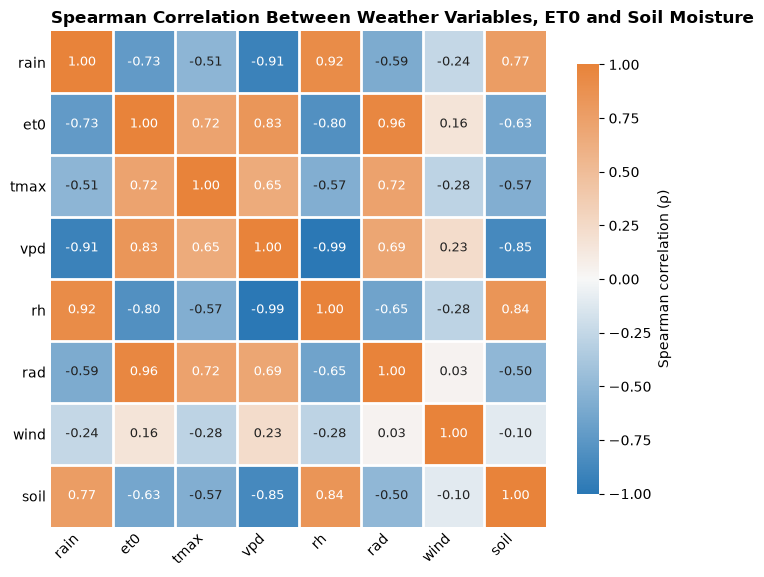

In [32]:
cmap_corr = LinearSegmentedColormap.from_list("blue_orange", [BLUE, "#f7f7f7", ORANGE])
corr = daily[cols].corr(method="spearman")     # Spearman: ฝนเบ้ขวาแรง

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap=cmap_corr, vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_yticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha="right"); ax.set_yticklabels(cols)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(len(cols)):
    for j in range(len(cols)):
        val = corr.iloc[i, j]
        ax.text(j, i, f"{round(val, 2) + 0.0:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(val) > 0.6 else "#222222")
ax.set_xticks([x - 0.5 for x in range(1, len(cols))], minor=True)
ax.set_yticks([y - 0.5 for y in range(1, len(cols))], minor=True)
ax.grid(False, which="major")
ax.grid(which="minor", color="white", linewidth=2)
ax.tick_params(which="both", length=0)
cb = fig.colorbar(im, ax=ax, shrink=0.8)
cb.set_label("Spearman correlation (ρ)"); cb.outline.set_visible(False)
ax.set_title("Spearman Correlation Between Weather Variables, ET0 and Soil Moisture", loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig("fig4_corr.png", dpi=200); plt.show()

## 8. สรุปความเสี่ยงภัยแล้งรายเดือน

month     1     2     3     4     5    6    7    8    9    10    11    12
year                                                                     
2020    61.0  93.0   0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0   0.0  45.0
2021   100.0  93.0   0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0   0.0  45.0
2022    68.0   0.0   0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0   0.0  42.0
2023    65.0  21.0  87.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0   0.0  55.0
2024   100.0  45.0   0.0  13.0  16.0  0.0  0.0  0.0  0.0  0.0  13.0  71.0
2025   100.0  57.0   0.0   0.0   0.0  0.0  0.0  0.0  0.0  0.0   7.0  45.0
2026    90.0  32.0   0.0  27.0   0.0  0.0  0.0  0.0  0.0  NaN   NaN   NaN
       soil_dry  water_deficit  dry_streak10  risk
month                                             
1          87.0           87.0          63.0  83.0
2          47.0           77.0          28.0  49.0
3          12.0           35.0           5.0  12.0
4           6.0           34.0           0.0   6.0
5           2.0            3

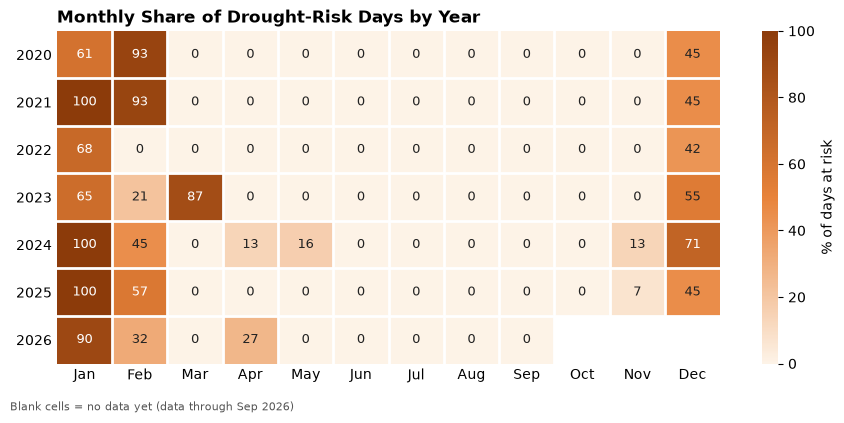

In [33]:
risk_table = daily.pivot_table(index="year", columns="month", values="risk", aggfunc="mean") * 100
print(risk_table.round(0))

# แยกดูว่าแต่ละเงื่อนไขเข้าเกณฑ์กี่ % ของวันในแต่ละเดือน
cond = pd.DataFrame({
    "soil_dry": daily["soil"] < soil_limit,
    "water_deficit": daily["balance14"] < -30,
    "dry_streak10": daily["dry_streak"] >= 10,
    "risk": daily["risk"],
})
print((cond.groupby(daily["month"]).mean() * 100).round(0))

cmap_risk = LinearSegmentedColormap.from_list("risk", ["#fdf3e7", ORANGE, "#8c3b0a"])
fig, ax = plt.subplots(figsize=(9, 4.2))
im = ax.imshow(risk_table, cmap=cmap_risk, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(risk_table.columns)))
ax.set_xticklabels([month_names[m - 1] for m in risk_table.columns])
ax.set_yticks(range(len(risk_table))); ax.set_yticklabels(risk_table.index)
for i in range(risk_table.shape[0]):
    for j in range(risk_table.shape[1]):
        val = risk_table.iloc[i, j]
        if val == val:
            ax.text(j, i, f"{val:.0f}", ha="center", va="center", fontsize=9,
                    color="white" if val > 55 else "#222222")
ax.set_xticks([x - 0.5 for x in range(1, len(risk_table.columns))], minor=True)
ax.set_yticks([y - 0.5 for y in range(1, len(risk_table))], minor=True)
ax.grid(False, which="major")
ax.grid(which="minor", color="white", linewidth=2)
ax.tick_params(which="both", length=0)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax)
cb.set_label("% of days at risk"); cb.outline.set_visible(False)
ax.set_title("Monthly Share of Drought-Risk Days by Year",
             loc="left", fontweight="bold")
last = daily.index.max()
fig.text(0.01, 0.01, f"Blank cells = no data yet (data through {last:%b %Y})", fontsize=8, color="#555")
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.savefig("fig5_risk.png", dpi=200); plt.show()

## 9. เปรียบเทียบ ET0 ระหว่างฤดูแล้งกับฤดูฝน

ใช้ Mann–Whitney U test และรายงานความสัมพันธ์แบบ Spearman

In [34]:
# แยกค่า ET0 ตามฤดูกาล
dry = daily.loc[daily["season"] == "dry", "et0"].dropna()
wet = daily.loc[daily["season"] == "wet", "et0"].dropna()

# ทดสอบความแตกต่างด้วย Mann–Whitney U
result = mannwhitneyu(dry, wet)
rank_biserial = 2 * result.statistic / (len(dry) * len(wet)) - 1

print(
    "มัธยฐาน ET0 แล้ง/ฝน:",
    round(dry.median(), 2),
    round(wet.median(), 2),
    "| p-value:",
    result.pvalue,
    "| rank-biserial =",
    round(rank_biserial, 2),
)

# ความสัมพันธ์แบบ Spearman ของตัวแปรกับ ET0
print(daily[cols].corr(method="spearman")["et0"].round(2))


มัธยฐาน ET0 แล้ง/ฝน: 4.38 3.4 | p-value: 3.332464721870077e-137 | rank-biserial = 0.58
rain   -0.73
et0     1.00
tmax    0.72
vpd     0.83
rh     -0.80
rad     0.96
wind    0.16
soil   -0.63
Name: et0, dtype: float64


## 10. Linear Regression: ความสัมพันธ์ระหว่างรังสีดวงอาทิตย์กับ ET0



slope = 0.0193 | intercept = -0.094 | R2 = 0.924


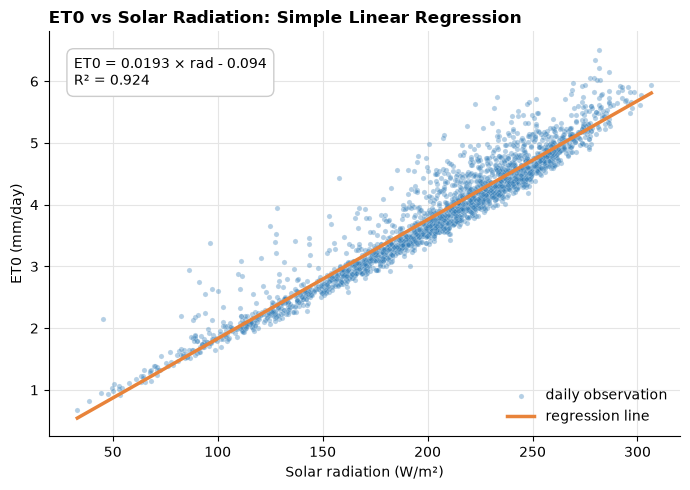

vpd     0.65
wind    0.60
tmax    0.02
dtype: float64


In [35]:
d = daily[["rad", "et0"]].dropna()
X, y_et = d[["rad"]], d["et0"]
model = LinearRegression().fit(X, y_et)
r2 = model.score(X, y_et)
print("slope =", round(model.coef_[0], 4), "| intercept =", round(model.intercept_, 3), "| R2 =", round(r2, 3))

x_line = pd.DataFrame({"rad": np.linspace(X["rad"].min(), X["rad"].max(), 100)})
y_line = model.predict(x_line)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(d["rad"], y_et, s=14, color=BLUE, alpha=0.35, edgecolor="white",
           linewidth=0.3, label="daily observation")
ax.plot(x_line["rad"], y_line, color=ORANGE, linewidth=2.5, label="regression line")
sign = "+" if model.intercept_ >= 0 else "-"
ax.text(0.04, 0.94, f"ET0 = {model.coef_[0]:.4f} × rad {sign} {abs(model.intercept_):.3f}\nR² = {r2:.3f}",
        transform=ax.transAxes, va="top", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="#cccccc"))
ax.set_xlabel("Solar radiation (W/m²)"); ax.set_ylabel("ET0 (mm/day)")
ax.set_title(f"ET0 vs Solar Radiation: Simple Linear Regression", loc="left", fontweight="bold")
ax.legend(loc="lower right", frameon=False)
plt.tight_layout()
plt.savefig("fig6_reg.png", dpi=200); plt.show()

# ดูว่าตัวแปรอื่นอธิบายส่วนที่เหลือ (residual) ได้ไหม
d2 = daily[["rad", "et0", "vpd", "wind", "tmax"]].dropna()
resid = d2["et0"] - model.predict(d2[["rad"]])
print(d2[["vpd", "wind", "tmax"]].corrwith(resid).round(2))

## 11. เปรียบเทียบสัมประสิทธิ์จาก Linear Regression หลายตัวแปร

rad     0.793
vpd     0.226
tmax    0.027
wind    0.100
dtype: float64


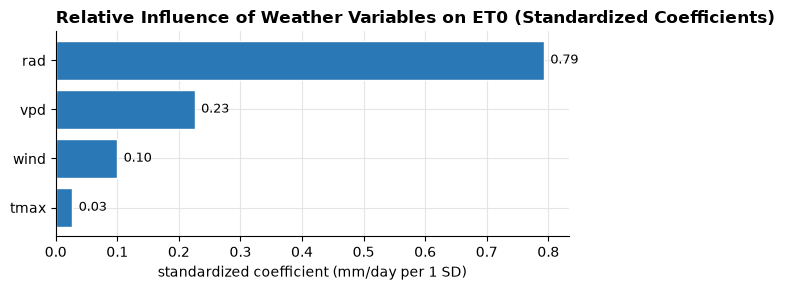

In [36]:
features = ["rad", "vpd", "tmax", "wind"]
d = daily[features + ["et0"]].dropna()
Z = (d[features] - d[features].mean()) / d[features].std()
all_model = LinearRegression().fit(Z, d["et0"])
coef = pd.Series(all_model.coef_, index=features)
print(coef.round(3))

c = coef.sort_values()
fig, ax = plt.subplots(figsize=(6, 3))
ax.barh(c.index, c.values, color=BLUE, edgecolor="white")
for i, val in enumerate(c.values):
    ax.text(val + 0.01, i, f"{val:.2f}", va="center", fontsize=9)
ax.set_xlabel("standardized coefficient (mm/day per 1 SD)")
ax.set_title("Relative Influence of Weather Variables on ET0 (Standardized Coefficients)", loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig("fig9_importance.png", dpi=200); plt.show()

## 12. ประเมิน Linear Regression เพื่อประมาณค่า ET0 ในช่วงข้อมูลที่กันไว้

ใช้ข้อมูลอากาศในวันเดียวกันเพื่อประมาณ ET0 ของวันนั้น จึงเป็นการประเมินโมเดล ไม่ใช่การพยากรณ์ ET0 ในอนาคต

['rad'] MAE = 0.188 | R2 = 0.932
['rad', 'vpd', 'wind'] MAE = 0.106 | R2 = 0.981
['rad', 'vpd', 'tmax', 'wind'] MAE = 0.106 | R2 = 0.981


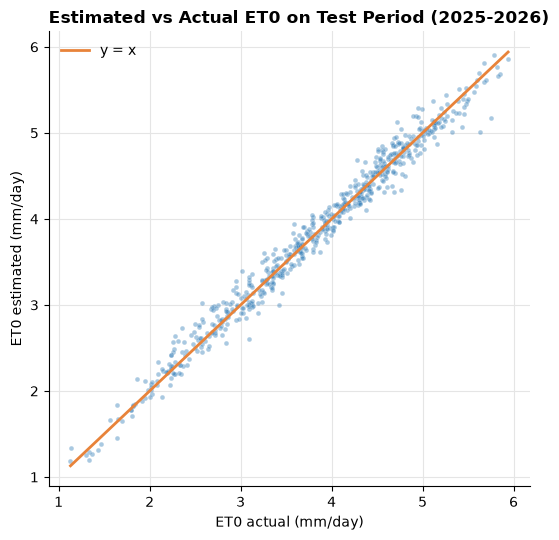

In [37]:
d = daily[features + ["et0"]].dropna()
tr_et, te_et = d[:"2024-12-31"], d["2025-01-01":]

for names in (["rad"], ["rad", "vpd", "wind"], features):
    m_et = LinearRegression().fit(tr_et[names], tr_et["et0"])
    p_et = m_et.predict(te_et[names])
    print(names, "MAE =", round(mean_absolute_error(te_et["et0"], p_et), 3),
          "| R2 =", round(r2_score(te_et["et0"], p_et), 3))

# scatter ของโมเดล 4 ตัวแปร (เส้น y = x)
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(te_et["et0"], p_et, s=12, color=BLUE, alpha=0.4, edgecolor="white", linewidth=0.3)
lim = [te_et["et0"].min(), te_et["et0"].max()]
ax.plot(lim, lim, color=ORANGE, lw=2, label="y = x")
ax.set_xlabel("ET0 actual (mm/day)"); ax.set_ylabel("ET0 estimated (mm/day)")
ax.set_title("Estimated vs Actual ET0 on Test Period (2025-2026)", loc="left", fontweight="bold")
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("fig10_et0_fit.png", dpi=200); plt.show()

n บวก/ลบ: 1263 1196
mean บวก/ลบ: 0.47 0.35 | median: 0.48 0.33
p-value: 5.923008709311165e-281 | rank-biserial = 0.83


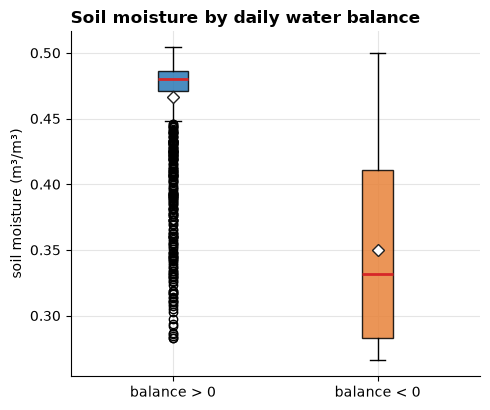

In [39]:
d = daily[["balance", "soil"]].dropna()
pos = d.loc[d["balance"] > 0, "soil"]
neg = d.loc[d["balance"] < 0, "soil"]
r = mannwhitneyu(pos, neg)
rrb = 2 * r.statistic / (len(pos) * len(neg)) - 1
print("n บวก/ลบ:", len(pos), len(neg))
print("mean บวก/ลบ:", round(pos.mean(), 2), round(neg.mean(), 2),
      "| median:", round(pos.median(), 2), round(neg.median(), 2))
print("p-value:", r.pvalue, "| rank-biserial =", round(rrb, 2))

fig, ax = plt.subplots(figsize=(5, 4.2))
bp = ax.boxplot([pos, neg], patch_artist=True, showmeans=True,
                medianprops=dict(color=MED_C, linewidth=2),
                meanprops=dict(marker="D", markerfacecolor="white", markeredgecolor=MEAN_C))
for box, c in zip(bp["boxes"], [BLUE, ORANGE]):
    box.set_facecolor(c); box.set_alpha(0.85)
ax.set_xticks([1, 2]); ax.set_xticklabels(["balance > 0", "balance < 0"])
ax.set_ylabel("soil moisture (m³/m³)")
ax.set_title("Soil moisture by daily water balance", loc="left", fontweight="bold")
plt.tight_layout(); plt.savefig("fig8_soil_balance.png", dpi=200); plt.show()

In [47]:
# ความสัมพันธ์แบบ Pearson ระหว่างตัวแปรกับ ET0
print(daily[cols].corr(method="pearson")["et0"].round(2))

# ความสัมพันธ์แบบ Spearman ระหว่างตัวแปรกับความชื้นดิน
cols_wb = cols + ["tmean", "balance14"]
print(daily[cols_wb].corr(method="spearman")[["soil"]].round(2))

rain   -0.67
et0     1.00
tmax    0.71
vpd     0.76
rh     -0.71
rad     0.96
wind    0.16
soil   -0.58
Name: et0, dtype: float64
           soil
rain       0.77
et0       -0.63
tmax      -0.57
vpd       -0.85
rh         0.84
rad       -0.50
wind      -0.10
soil       1.00
tmean     -0.24
balance14  0.90


In [42]:

# ==========================================
# 14. Linear vs Polynomial Regression
# Target: soil moisture
# Feature: water balance accumulated over 14 days
# ==========================================

# 1) เตรียมข้อมูล
model_data = daily[["balance14", "soil"]].dropna().copy()

X = model_data[["balance14"]]
y = model_data["soil"]

# 2) แบ่งข้อมูลตามลำดับเวลา 80:20
# ไม่สุ่มข้อมูล เพื่อให้ชุดทดสอบเป็นข้อมูลช่วงหลัง
split_idx = int(len(model_data) * 0.80)

X_train = X.iloc[:split_idx]
X_test = X.iloc[split_idx:]

y_train = y.iloc[:split_idx]
y_test = y.iloc[split_idx:]

print("จำนวนข้อมูลทั้งหมด:", len(model_data))
print("Train:", len(X_train))
print("Test:", len(X_test))
print("ช่วง Train:", X_train.index.min(), "ถึง", X_train.index.max())
print("ช่วง Test:", X_test.index.min(), "ถึง", X_test.index.max())

# 3) สร้างแบบจำลอง
linear_model = LinearRegression()

polynomial_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

# 4) ฝึกแบบจำลองด้วยข้อมูล Train
linear_model.fit(X_train, y_train)
polynomial_model.fit(X_train, y_train)

# 5) ประมาณค่าความชื้นในดินของข้อมูล Test
pred_linear = linear_model.predict(X_test)
pred_poly = polynomial_model.predict(X_test)

# 6) ประเมินประสิทธิภาพ
def evaluate_model(name, y_true, y_pred):
    return {
        "Model": name,
        "R2": r2_score(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred)
    }

results = pd.DataFrame([
    evaluate_model("Linear Regression", y_test, pred_linear),
    evaluate_model("Polynomial Regression (degree 2)", y_test, pred_poly)
])

print("\nผลการเปรียบเทียบแบบจำลอง")
print(results.round(4).to_string(index=False))

# 7) สรุปแบบจำลองที่มีผลดีกว่าในชุด Test
best_r2 = results.loc[results["R2"].idxmax(), "Model"]
best_rmse = results.loc[results["RMSE"].idxmin(), "Model"]
best_mae = results.loc[results["MAE"].idxmin(), "Model"]

print("\nแบบจำลองที่มี R2 สูงที่สุด:", best_r2)
print("แบบจำลองที่มี RMSE ต่ำที่สุด:", best_rmse)
print("แบบจำลองที่มี MAE ต่ำที่สุด:", best_mae)


จำนวนข้อมูลทั้งหมด: 2446
Train: 1956
Test: 490
ช่วง Train: 2020-01-14 00:00:00 ถึง 2025-05-22 00:00:00
ช่วง Test: 2025-05-23 00:00:00 ถึง 2026-09-24 00:00:00

ผลการเปรียบเทียบแบบจำลอง
                           Model    R2   RMSE    MAE
               Linear Regression 0.783 0.0377 0.0315
Polynomial Regression (degree 2) 0.931 0.0213 0.0167

แบบจำลองที่มี R2 สูงที่สุด: Polynomial Regression (degree 2)
แบบจำลองที่มี RMSE ต่ำที่สุด: Polynomial Regression (degree 2)
แบบจำลองที่มี MAE ต่ำที่สุด: Polynomial Regression (degree 2)


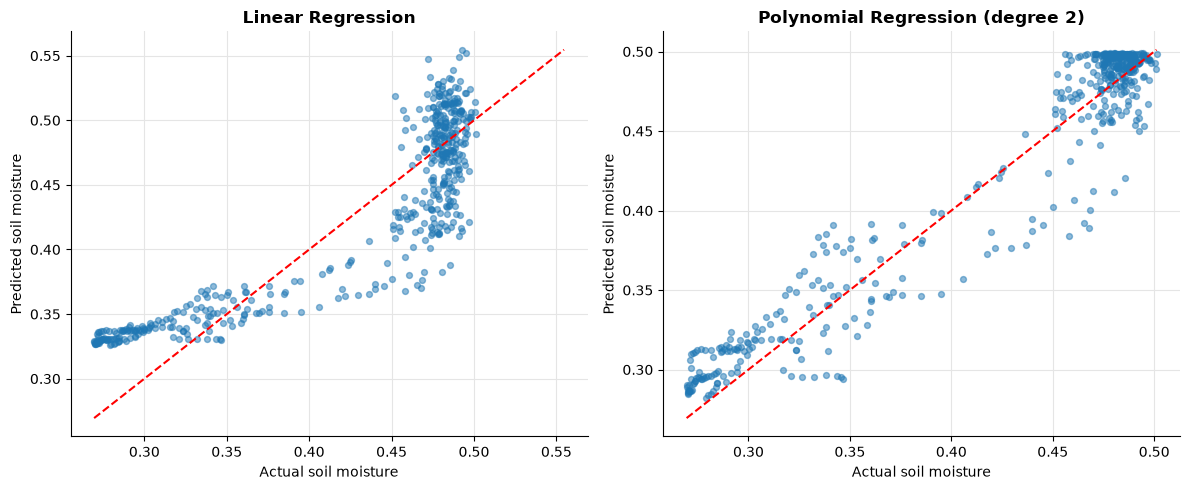

In [44]:

# รวมผลการประมาณค่ากับค่าจริง
comparison = pd.DataFrame({
    "Actual": y_test,
    "Linear": pred_linear,
    "Polynomial": pred_poly
}, index=y_test.index)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# กราฟ 1: ค่าจริงเทียบกับ Linear Regression
axes[0].scatter(
    comparison["Actual"], comparison["Linear"],
    alpha=0.5, s=18
)

low = min(comparison["Actual"].min(),
          comparison["Linear"].min())
high = max(comparison["Actual"].max(),
           comparison["Linear"].max())

axes[0].plot([low, high], [low, high], "r--")
axes[0].set_xlabel("Actual soil moisture")
axes[0].set_ylabel("Predicted soil moisture")
axes[0].set_title("Linear Regression")

# กราฟ 2: ค่าจริงเทียบกับ Polynomial Regression
axes[1].scatter(
    comparison["Actual"], comparison["Polynomial"],
    alpha=0.5, s=18
)

low = min(comparison["Actual"].min(),
          comparison["Polynomial"].min())
high = max(comparison["Actual"].max(),
           comparison["Polynomial"].max())

axes[1].plot([low, high], [low, high], "r--")
axes[1].set_xlabel("Actual soil moisture")
axes[1].set_ylabel("Predicted soil moisture")
axes[1].set_title("Polynomial Regression (degree 2)")

plt.tight_layout()
plt.savefig("fig11_soil_model_comparison.png", dpi=200)
plt.show()


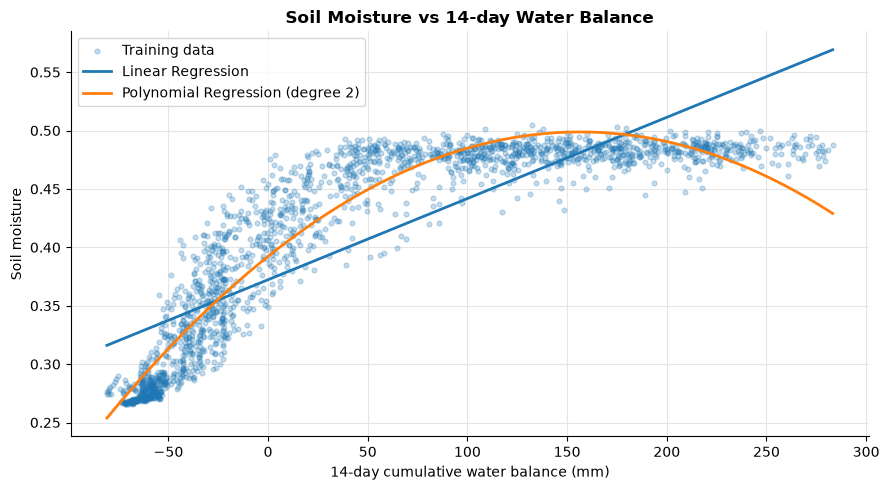

In [43]:


# เรียงค่า X สำหรับวาดเส้นแบบจำลอง
x_grid = np.linspace(
    X_train["balance14"].min(),
    X_train["balance14"].max(),
    200
).reshape(-1, 1)

x_grid_df = pd.DataFrame(
    x_grid, columns=["balance14"]
)

plt.figure(figsize=(9, 5))

plt.scatter(
    X_train["balance14"], y_train,
    alpha=0.25, s=12, label="Training data"
)

plt.plot(
    x_grid.ravel(),
    linear_model.predict(x_grid_df),
    linewidth=2,
    label="Linear Regression"
)

plt.plot(
    x_grid.ravel(),
    polynomial_model.predict(x_grid_df),
    linewidth=2,
    label="Polynomial Regression (degree 2)"
)

plt.xlabel("14-day cumulative water balance (mm)")
plt.ylabel("Soil moisture")
plt.title("Soil Moisture vs 14-day Water Balance")
plt.legend()
plt.tight_layout()
plt.savefig("fig12_soil_regression_curves.png", dpi=200)
plt.show()


## 13. สรุปรายปีและกราฟแนวโน้ม

ปี 2026 มีข้อมูลไม่ครบปี จึงไม่ควรเปรียบเทียบปริมาณฝนรวมกับปีเต็มโดยตรง

       ฝนรวม  วันเสี่ยง  แล้งยาวสุด
year                               
2020  2550.0         60          21
2021  2830.0         71          54
2022  3118.0         34          25
2023  2800.0         70          28
2024  2685.0         79          47
2025  2960.0         63          63
2026  2292.0         45          36
หมายเหตุ: ปีสุดท้ายข้อมูลไม่ครบปี ห้ามเทียบฝนรวมกับปีอื่นตรงๆ


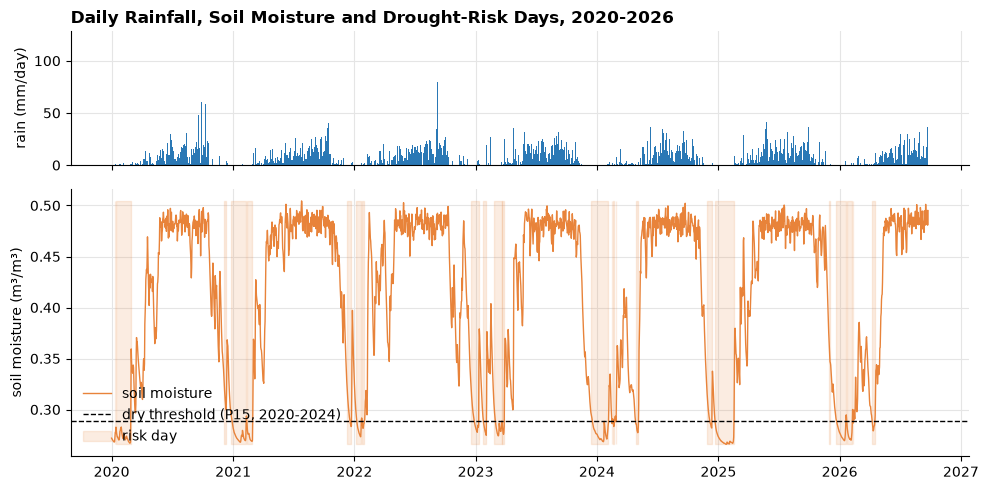

In [48]:
# ---------- สรุปรายปี ----------
print(daily.groupby("year").agg(
    ฝนรวม=("rain", "sum"), วันเสี่ยง=("risk", "sum"), แล้งยาวสุด=("dry_streak", "max"),
).round(0))
print("หมายเหตุ: ปีสุดท้ายข้อมูลไม่ครบปี ห้ามเทียบฝนรวมกับปีอื่นตรงๆ")

# ---------- กราฟ A: อนุกรมเวลา ----------
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True,
                             gridspec_kw={"height_ratios": [1, 2]})
a1.bar(daily.index, daily["rain"], color=BLUE, width=1)
a1.set_ylabel("rain (mm/day)")
a2.plot(daily.index, daily["soil"], color=ORANGE, lw=1, label="soil moisture")
a2.axhline(soil_limit, color="black", ls="--", lw=1, label="dry threshold (P15, 2020-2024)")
a2.fill_between(daily.index, daily["soil"].min(), daily["soil"].max(),
                where=daily["risk"].to_numpy(), color=ORANGE, alpha=0.15, label="risk day")
a2.set_ylabel("soil moisture (m³/m³)")
a2.legend(frameon=False, loc="lower left")
a1.set_title("Daily Rainfall, Soil Moisture and Drought-Risk Days, 2020-2026", loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig("fig7_timeseries.png", dpi=200); plt.show()

